# Experiment 9: Association Rule Mining using Python
## Apriori Algorithm — Airline Passenger Satisfaction

**Aim:** Find frequent combinations of passenger and service attributes, and the association rules between them (for example *Business class + business travel → satisfied*), using the Apriori algorithm.

**How to run**
- Run this notebook in **Google Colab**. When the load cell asks, choose `train.csv`.
- The first cell installs `mlxtend` if it is missing. This needs an internet connection.
- Run every cell **once, top to bottom**, and take each screenshot straight after its cell runs.

**Screenshots required (8):** 1 = transactions, 2 = item frequency, 3 = frequent itemsets, 4 = association rules, 5 = rules for satisfaction, 6 = support vs confidence, 7 = effect of min_support, 8 = key findings. The other cells need no screenshot.

**Measures used**
- **Support** = share of passengers that have all the items of the rule.
- **Confidence** = among passengers that have the *antecedent* items, the share that also have the *consequent* item.
- **Lift** = confidence divided by the overall support of the consequent. A lift above 1 means the items occur together more often than by chance.

In [ ]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)   # hides the harmless Colab 'utcnow' warnings
warnings.filterwarnings('ignore', message='.*utcnow.*')

import sys, subprocess, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

try:
    import mlxtend
except ImportError:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'mlxtend'])
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
print('Libraries imported successfully.')

Libraries imported successfully.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## Load the dataset
Run the cell, click **Choose files**, and select `train.csv`. No screenshot needed.

In [ ]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

from google.colab import files
uploaded = files.upload()

if len(uploaded) > 0:
    df = pd.read_csv(list(uploaded.keys())[0])
    print('Loaded | shape:', df.shape)
    display(df.head())
else:
    print('No file uploaded. Please run the cell again and choose train.csv.')

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saving train.csv to train.csv
Loaded | shape: (103904, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


## Prepare the transactions — Screenshot 1
Apriori works on *items*, so every passenger becomes a transaction. Numeric columns are grouped into bands (age group, flight distance, rating level, delay), and every value becomes an item such as `Class=Business`. A rating of 0 means *not applicable* in this dataset, so it creates no item. The result is a True/False table with one column per item.

In [ ]:
rating_cols = ['Online boarding', 'Inflight wifi service', 'Inflight entertainment',
               'Seat comfort', 'Cleanliness', 'Leg room service']

items_df = pd.DataFrame(index=df.index)
items_df['Gender'] = df['Gender']
items_df['Customer Type'] = df['Customer Type'].replace({'Loyal Customer': 'Loyal', 'disloyal Customer': 'Disloyal'})
items_df['Type of Travel'] = df['Type of Travel'].replace({'Business travel': 'Business', 'Personal Travel': 'Personal'})
items_df['Class'] = df['Class']
items_df['Age'] = pd.cut(df['Age'], bins=[0, 24, 44, 64, 120], labels=['Under 25', '25-44', '45-64', '65+'])
items_df['Flight Distance'] = pd.cut(df['Flight Distance'], bins=[0, 800, 2000, 10000], labels=['Short', 'Medium', 'Long'])
for c in rating_cols:
    items_df[c] = pd.cut(df[c], bins=[0, 2, 3, 5], labels=['Low', 'Medium', 'High'])   # 1-2 Low, 3 Medium, 4-5 High
items_df['Departure Delay'] = pd.cut(df['Departure Delay in Minutes'], bins=[-1, 0, 30, np.inf],
                                     labels=['None', 'Short (1-30 min)', 'Long (over 30 min)'])
items_df['satisfaction'] = df['satisfaction']

basket = pd.get_dummies(items_df, prefix_sep='=', dtype=bool)
print('Transactions:', len(basket), '| Items:', basket.shape[1],
      '| Average items per transaction:', round(basket.sum(axis=1).mean(), 1))
print('Columns turned into items:', list(items_df.columns))
display(items_df.head())

Transactions: 103904 | Items: 39 | Average items per transaction: 13.9
Columns turned into items: ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Age', 'Flight Distance', 'Online boarding', 'Inflight wifi service', 'Inflight entertainment', 'Seat comfort', 'Cleanliness', 'Leg room service', 'Departure Delay', 'satisfaction']


,Gender,Customer Type,Type of Travel,Class,Age,Flight Distance,Online boarding,Inflight wifi service,Inflight entertainment,Seat comfort,Cleanliness,Leg room service,Departure Delay,satisfaction
0,Male,Loyal,Personal,Eco Plus,Under 25,Short,Medium,Medium,High,High,High,Medium,Short (1-30 min),neutral or dissatisfied
1,Male,Disloyal,Business,Business,25-44,Short,Medium,Medium,Low,Low,Low,High,Short (1-30 min),neutral or dissatisfied
2,Female,Loyal,Business,Business,25-44,Medium,High,Low,High,High,High,Medium,None,satisfied
3,Female,Loyal,Business,Business,25-44,Short,Low,Low,Low,Low,Low,High,Short (1-30 min),neutral or dissatisfied
4,Male,Loyal,Business,Business,45-64,Short,High,Medium,Medium,High,Medium,High,None,satisfied


## Item frequency — Screenshot 2
The support of an item is the share of passengers that have it.

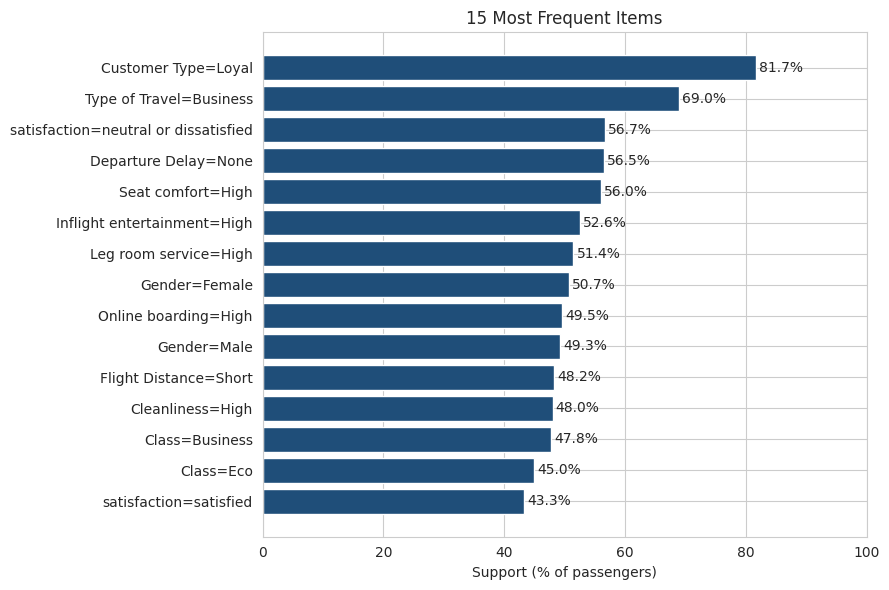

Satisfied passengers overall: 43.3%


In [ ]:
item_support = basket.mean().sort_values(ascending=False)
top = item_support.head(15).sort_values()

plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values * 100, color='#1F4E79')
for i, v in enumerate(top.values * 100):
    plt.text(v + 0.5, i, f'{v:.1f}%', va='center')
plt.xlim(0, 100)
plt.title('15 Most Frequent Items'); plt.xlabel('Support (% of passengers)')
plt.tight_layout(); plt.show()
print(f"Satisfied passengers overall: {item_support['satisfaction=satisfied'] * 100:.1f}%")

## Apriori: frequent itemsets — Screenshot 3
Apriori finds every combination of items whose support is at least `MIN_SUPPORT`. It starts with single items, keeps only the frequent ones, and builds larger combinations from them. `MAX_LEN` limits the size of an itemset.

In [ ]:
MIN_SUPPORT = 0.10
MIN_CONFIDENCE = 0.60
MAX_LEN = 3

t0 = time.perf_counter()
frequent_itemsets = apriori(basket, min_support=MIN_SUPPORT, use_colnames=True, max_len=MAX_LEN)
apriori_time = time.perf_counter() - t0
frequent_itemsets['size'] = frequent_itemsets['itemsets'].apply(len)
frequent_itemsets['itemset'] = frequent_itemsets['itemsets'].apply(lambda s: ' AND '.join(sorted(s)))

print(f'min_support = {MIN_SUPPORT} | max itemset size = {MAX_LEN} | time = {apriori_time:.1f} s')
print('Frequent itemsets found:', len(frequent_itemsets))
print(frequent_itemsets['size'].value_counts().sort_index().rename('number of itemsets').to_frame().rename_axis('itemset size').T.to_string())
print('\nTop 10 itemsets with two or more items:')
display(frequent_itemsets[frequent_itemsets['size'] >= 2].sort_values('support', ascending=False)
        .head(10)[['itemset', 'support']].round(3).reset_index(drop=True))

min_support = 0.1 | max itemset size = 3 | time = 1.3 s
Frequent itemsets found: 1291
itemset size         1    2    3
number of itemsets  37  357  897

Top 10 itemsets with two or more items:


,itemset,support
0,Customer Type=Loyal AND Type of Travel=Business,0.509
1,Customer Type=Loyal AND Seat comfort=High,0.488
2,Customer Type=Loyal AND Departure Delay=None,0.462
3,Class=Business AND Type of Travel=Business,0.457
4,Customer Type=Loyal AND Inflight entertainment=High,0.451
5,Inflight entertainment=High AND Seat comfort=High,0.444
6,Customer Type=Loyal AND Online boarding=High,0.441
7,Customer Type=Loyal AND Leg room service=High,0.433
8,Customer Type=Loyal AND satisfaction=neutral or dissatisfied,0.427
9,Cleanliness=High AND Seat comfort=High,0.420


## Association rules — Screenshot 4
Every frequent itemset is split into an *antecedent* (IF part) and a *consequent* (THEN part). Rules with confidence of at least `MIN_CONFIDENCE` are kept.

In [ ]:
try:
    rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=MIN_CONFIDENCE)
except TypeError:      # newer mlxtend versions also need the number of transactions
    rules = association_rules(frequent_itemsets, num_itemsets=len(basket), metric='confidence', min_threshold=MIN_CONFIDENCE)

rules['rule'] = (rules['antecedents'].apply(lambda s: ' AND '.join(sorted(s)))
                 + '  =>  ' + rules['consequents'].apply(lambda s: ' AND '.join(sorted(s))))

def show_rules(table, n=10):
    cols = ['rule', 'support', 'confidence', 'lift']
    display(table.head(n)[cols].round(3).reset_index(drop=True))

print(f'Rules found (confidence >= {MIN_CONFIDENCE}): {len(rules):,}')
print(f'Rules with lift > 1: {(rules["lift"] > 1).sum():,}')
print('\nTop 10 rules by lift:')
show_rules(rules.sort_values(['lift', 'confidence'], ascending=False))

Rules found (confidence >= 0.6): 1,498
Rules with lift > 1: 1,322

Top 10 rules by lift:


,rule,support,confidence,lift
0,Cleanliness=Medium AND Seat comfort=Medium => Inflight entertainment=Medium,0.100,0.861,4.672
1,Cleanliness=Medium AND Inflight entertainment=Medium => Seat comfort=Medium,0.100,0.761,4.231
2,Cleanliness=Medium AND satisfaction=neutral or dissatisfied => Inflight entertainment=Medium,0.102,0.762,4.135
3,Inflight entertainment=Medium AND Seat comfort=Medium => Cleanliness=Medium,0.100,0.900,3.805
4,Inflight wifi service=Medium AND satisfaction=neutral or dissatisfied => Online boarding=Medium,0.136,0.727,3.465
5,Online boarding=Medium => Inflight wifi service=Medium AND satisfaction=neutral or dissatisfied,0.136,0.646,3.465
6,Inflight entertainment=Low AND Seat comfort=Low => Cleanliness=Low,0.186,0.970,3.424
7,Cleanliness=Low => Inflight entertainment=Low AND Seat comfort=Low,0.186,0.655,3.424
8,Inflight entertainment=Low AND Online boarding=Low => Seat comfort=Low,0.107,0.876,3.374
9,Seat comfort=Medium => Inflight entertainment=Medium,0.112,0.621,3.369


## Rules for satisfaction — Screenshot 5
Only rules whose THEN part is the satisfaction result are shown, sorted by lift.

In [ ]:
sat_rules = rules[rules['consequents'] == frozenset({'satisfaction=satisfied'})].sort_values(['lift', 'confidence'], ascending=False)
dis_rules = rules[rules['consequents'] == frozenset({'satisfaction=neutral or dissatisfied'})].sort_values(['lift', 'confidence'], ascending=False)

print(f'Rules that lead to SATISFIED: {len(sat_rules):,}  (top 8 by lift)')
show_rules(sat_rules, 8)
print(f'\nRules that lead to NEUTRAL OR DISSATISFIED: {len(dis_rules):,}  (top 8 by lift)')
show_rules(dis_rules, 8)

Rules that lead to SATISFIED: 80  (top 8 by lift)


,rule,support,confidence,lift
0,Flight Distance=Long AND Inflight entertainment=High => satisfaction=satisfied,0.118,0.887,2.046
1,Class=Business AND Online boarding=High => satisfaction=satisfied,0.283,0.881,2.032
2,Flight Distance=Long AND Online boarding=High => satisfaction=satisfied,0.123,0.877,2.024
3,Class=Business AND Inflight entertainment=High => satisfaction=satisfied,0.265,0.874,2.018
4,Class=Business AND Inflight wifi service=High => satisfaction=satisfied,0.140,0.871,2.010
5,Leg room service=High AND Online boarding=High => satisfaction=satisfied,0.255,0.863,1.993
6,Flight Distance=Long AND Leg room service=High => satisfaction=satisfied,0.114,0.860,1.985
7,Flight Distance=Long AND Seat comfort=High => satisfaction=satisfied,0.124,0.858,1.980



Rules that lead to NEUTRAL OR DISSATISFIED: 114  (top 8 by lift)


,rule,support,confidence,lift
0,Inflight wifi service=Low AND Type of Travel=Personal => satisfaction=neutral or dissatisfied,0.148,1.000,1.765
1,Class=Eco AND Inflight wifi service=Low => satisfaction=neutral or dissatisfied,0.194,0.987,1.741
2,Online boarding=Low AND Type of Travel=Personal => satisfaction=neutral or dissatisfied,0.113,0.982,1.732
3,Class=Eco AND Inflight wifi service=Medium => satisfaction=neutral or dissatisfied,0.123,0.975,1.721
4,Inflight wifi service=Medium AND Online boarding=Medium => satisfaction=neutral or dissatisfied,0.136,0.955,1.686
5,Inflight wifi service=Low AND Online boarding=Low => satisfaction=neutral or dissatisfied,0.217,0.953,1.682
6,Class=Eco AND Online boarding=Low => satisfaction=neutral or dissatisfied,0.160,0.950,1.677
7,Class=Eco AND Online boarding=Medium => satisfaction=neutral or dissatisfied,0.112,0.947,1.671


## Support vs confidence — Screenshot 6
Each dot is a rule. The colour shows the lift.

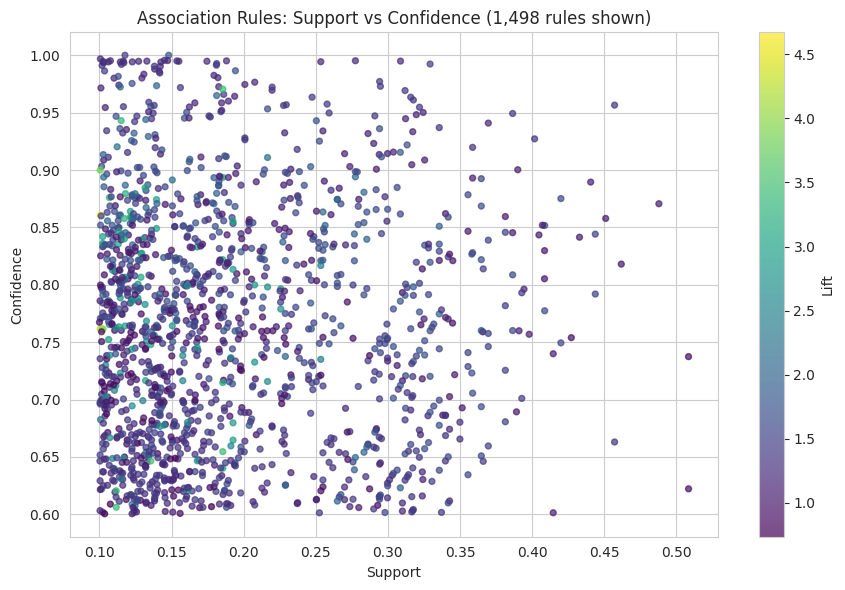

In [ ]:
plot_rules = rules.sample(min(len(rules), 5000), random_state=42) if len(rules) else rules
plt.figure(figsize=(9, 6))
sc = plt.scatter(plot_rules['support'], plot_rules['confidence'], c=plot_rules['lift'], cmap='viridis', s=18, alpha=0.7)
plt.colorbar(sc, label='Lift')
plt.title(f'Association Rules: Support vs Confidence ({len(plot_rules):,} rules shown)')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.tight_layout(); plt.show()

## Effect of min_support — Screenshot 7
A lower `min_support` finds more itemsets and rules but takes longer. This cell repeats Apriori with higher thresholds.

,Frequent itemsets,Rules,Time (s)
min_support,,,
0.30,101,193,0.1
0.25,185,350,0.2
0.20,324,516,0.4
0.15,621,877,0.7
0.10,1291,1498,1.3


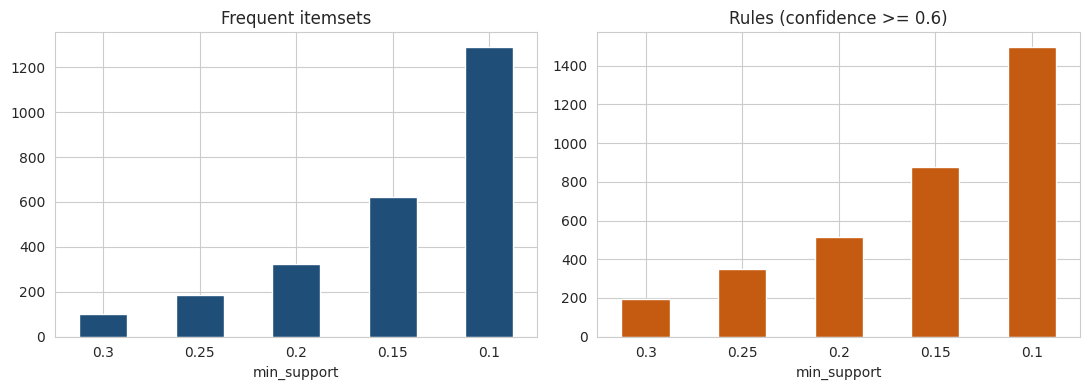

In [ ]:
rows = []
for ms in sorted({0.30, 0.25, 0.20, 0.15, MIN_SUPPORT}, reverse=True):
    if ms == MIN_SUPPORT:
        n_items, n_rules, secs = len(frequent_itemsets), len(rules), apriori_time
    else:
        t0 = time.perf_counter()
        fi = apriori(basket, min_support=ms, use_colnames=True, max_len=MAX_LEN)
        secs = time.perf_counter() - t0
        try:
            r = association_rules(fi, metric='confidence', min_threshold=MIN_CONFIDENCE) if len(fi) else []
        except TypeError:
            r = association_rules(fi, num_itemsets=len(basket), metric='confidence', min_threshold=MIN_CONFIDENCE) if len(fi) else []
        n_items, n_rules = len(fi), len(r)
    rows.append({'min_support': ms, 'Frequent itemsets': n_items, 'Rules': n_rules, 'Time (s)': round(secs, 1)})
sens = pd.DataFrame(rows).set_index('min_support')
display(sens)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sens['Frequent itemsets'].plot(kind='bar', ax=ax[0], color='#1F4E79'); ax[0].set_title('Frequent itemsets'); ax[0].tick_params(axis='x', rotation=0)
sens['Rules'].plot(kind='bar', ax=ax[1], color='#C55A11'); ax[1].set_title(f'Rules (confidence >= {MIN_CONFIDENCE})'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

## Key findings — Screenshot 8
The strongest rules written in plain English.

In [ ]:
base = item_support['satisfaction=satisfied']
print(f'Overall, {base * 100:.1f}% of passengers are satisfied.\n')

def say(r):
    return (f"IF {' AND '.join(sorted(r.antecedents))}  THEN {' AND '.join(sorted(r.consequents))}\n"
            f"     support {r.support * 100:.1f}% | confidence {r.confidence * 100:.1f}% | lift {r.lift:.2f}")

print('Strongest rules for SATISFIED passengers:')
for r in sat_rules.head(4).itertuples():
    print(' *', say(r))
print('\nStrongest rules for NEUTRAL OR DISSATISFIED passengers:')
for r in dis_rules.head(4).itertuples():
    print(' *', say(r))

Overall, 43.3% of passengers are satisfied.

Strongest rules for SATISFIED passengers:
 * IF Flight Distance=Long AND Inflight entertainment=High  THEN satisfaction=satisfied
     support 11.8% | confidence 88.7% | lift 2.05
 * IF Class=Business AND Online boarding=High  THEN satisfaction=satisfied
     support 28.3% | confidence 88.1% | lift 2.03
 * IF Flight Distance=Long AND Online boarding=High  THEN satisfaction=satisfied
     support 12.3% | confidence 87.7% | lift 2.02
 * IF Class=Business AND Inflight entertainment=High  THEN satisfaction=satisfied
     support 26.5% | confidence 87.4% | lift 2.02

Strongest rules for NEUTRAL OR DISSATISFIED passengers:
 * IF Inflight wifi service=Low AND Type of Travel=Personal  THEN satisfaction=neutral or dissatisfied
     support 14.8% | confidence 100.0% | lift 1.76
 * IF Class=Eco AND Inflight wifi service=Low  THEN satisfaction=neutral or dissatisfied
     support 19.4% | confidence 98.7% | lift 1.74
 * IF Online boarding=Low AND Type of

## Result
The Apriori algorithm was applied to passenger transactions built from the airline data. Record the number of frequent itemsets and rules, the strongest rules for satisfied and for neutral or dissatisfied passengers (with their support, confidence and lift), and the effect of `min_support` from the outputs above. A rule is useful when its lift is clearly above 1 and its support is large enough to apply to many passengers.